# Step 3 — our LOCO design with the 86 features of Dang et al. (2024) instead of ours

Same people (our 33,498), same outcome, same folds, models and grids as step 1; only the feature set changes. This separates "better features" from "different evaluation" when comparing with the paper (its NHANES LR: AUROC 0.793, random 10-fold).

**Input** (with `RUN`): the paper's feature table `FullData_rm_dl_bt.csv`, built in our reproduction of the paper (not part of this repo); set its path in `PAPER1_CSV` or the environment variable of the same name. See `nhanes/paper1.py` for how its columns are read.

**Output:** `$NHANES_WORK/modeling/step3_paper1/` (same files as step 1)

`RUN = True` retrains (about 2 hours); `QUICK = True` with it runs one outer fold with the smallest grids. `RUN = False` only shows the saved results.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS, WORK  # noqa: E402

RUN = False    # True: retrain and overwrite $NHANES_WORK/modeling/step3_paper1
QUICK = False  # with RUN: one outer fold, smallest grids
PAPER1_CSV = os.environ.get("PAPER1_CSV")  # FullData_rm_dl_bt.csv of the paper1 reproduction (needed with RUN)
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / "step3_paper1"

## Run

In [2]:
if RUN:
    from nhanes.loco import NOT_FEATURES, run_loco
    from nhanes.paper1 import paper1_table
    feats, dic = paper1_table(PAPER1_CSV)
    ours = pd.read_csv(WORK / "features" / "features_2005_2018.csv.gz", usecols=NOT_FEATURES)
    data = ours.merge(feats, on="SEQN", how="left", validate="1:1")
    assert data[list(dic)].notna().any(axis=1).all(), "some of our participants are missing from the paper's table"
    print(f"{len(data)} people, {len(dic)} features "
          f"({sum(v == 'categorical' for v in dic.values())} categorical)", flush=True)
    run_loco(data, dic, OUT, QUICK,
             title="leave-one-cycle-out, outcome PHQ-9 >= 10; features of Dang et al. (2024), our population")

## Results, next to step 1 (our 317 features)

In [3]:
print((OUT / "report.txt").read_text())

leave-one-cycle-out, outcome PHQ-9 >= 10; features of Dang et al. (2024), our population

mean (sd) over test cycles, each cycle weighted equally:
         auroc        auroc_weighted         auprc         brier       
          mean    std           mean    std   mean    std   mean    std
model                                                                  
logreg   0.792  0.014          0.796  0.013  0.322  0.033  0.179  0.009
xgboost  0.791  0.013          0.796  0.014  0.316  0.027  0.172  0.007

AUROC of all out-of-cycle predictions pooled:
model
logreg     0.79
xgboost    0.79

per test cycle:
  model test_cycle  auroc  auroc_weighted  auprc  brier    n  prevalence  minutes
 logreg    2005-06  0.802           0.816  0.282  0.178 3975       0.062      6.6
xgboost    2005-06  0.803           0.822  0.300  0.168 3975       0.062      0.5
 logreg    2007-08  0.800           0.803  0.356  0.180 5104       0.098      5.5
xgboost    2007-08  0.794           0.798  0.346  0.178 5104   

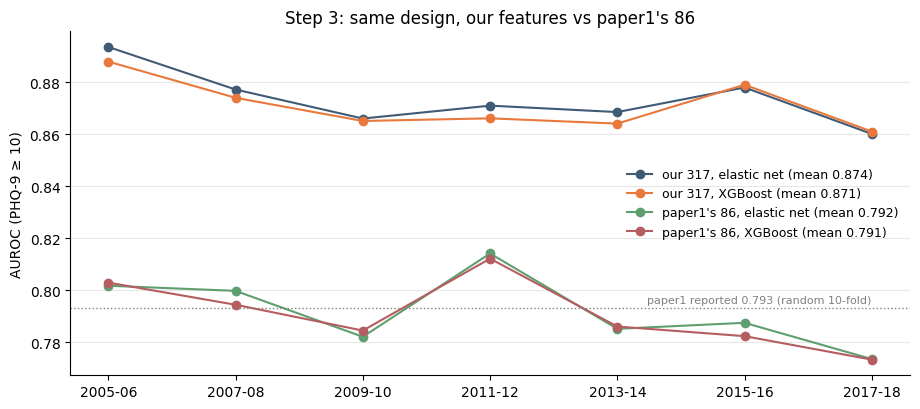

In [4]:
ours = pd.read_csv(RESULTS / "step1" / "metrics.csv").assign(model=lambda m: "ours " + m.model)
paper = pd.read_csv(OUT / "metrics.csv").assign(model=lambda m: "paper1 " + m.model)
met = pd.concat([ours, paper], ignore_index=True)
names = {"ours logreg": "our 317, elastic net", "ours xgboost": "our 317, XGBoost",
         "paper1 logreg": "paper1's 86, elastic net", "paper1 xgboost": "paper1's 86, XGBoost"}
ax = plots.per_split_auroc(met, labels=names, title="Step 3: same design, our features vs paper1's 86")
ax.axhline(0.793, color="grey", ls=":", lw=1)
ax.text(len(met.test_cycle.unique()) - 1, 0.795, "paper1 reported 0.793 (random 10-fold)", ha="right", fontsize=8, color="grey")
plots.show()